Energy Data Science ITS8080

Assignment 10: Forecasting pipeline and uncertainty

Student:Mihhail Korasteljov  

Load and clean the data

In [1]:
# Load the data. Keep a regular hourly UTC time index.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error
from statsmodels.tsa.statespace.sarimax import SARIMAX
from IPython.display import display

TRAIN_FILE = Path("266050_training.csv")
FORECAST_FILE = Path("266050_forecast.csv")

def read_demand(path):
    d = pd.read_csv(path, usecols=["timestamp", "Demand"])
    d["timestamp"] = pd.to_datetime(d["timestamp"], utc=True)
    d = d.set_index("timestamp").sort_index()
    if d.index.has_duplicates:
        raise ValueError("Duplicate timestamps")
    return d["Demand"].astype(float)

train_raw = read_demand(TRAIN_FILE)
test_raw = read_demand(FORECAST_FILE)
assert len(test_raw) == 168, "Expected 7 days × 24 hours"
assert test_raw.index[0] == train_raw.index.max() + pd.Timedelta(hours=1)

# Fill missing training timestamps and values without looking into future test data.
train_index = pd.date_range(train_raw.index.min(), train_raw.index.max(), freq="h", tz="UTC")
train = train_raw.reindex(train_index).ffill().bfill().clip(lower=0)
test = test_raw.asfreq("h")
assert test.notna().all()
assert len(test) == 7*24
train_mean = train.mean()
print("Training:", train.index.min(), "to", train.index.max(), "hours:", len(train))
print("Forecast:", test.index.min(), "to", test.index.max(), "hours:", len(test))
print("Training mean [kW]:", round(train_mean, 4))

def score(actual, predicted):
    a, f = np.asarray(actual), np.asarray(predicted)
    return {"MAE [kW]": np.mean(np.abs(a-f)),
            "nRMSE [%]": 100*np.sqrt(np.mean((a-f)**2))/train_mean}


Training: 2013-07-01 00:00:00+00:00 to 2014-06-30 23:00:00+00:00 hours: 8760
Forecast: 2014-07-01 00:00:00+00:00 to 2014-07-07 23:00:00+00:00 hours: 168
Training mean [kW]: 0.5311



**Task 10.1.** Provide an out-of-sample forecast of hourly demand for 7 days.

(a) Use a rolling out-of-sample forecasting approach (i.e., forecast day-by-day) with a 24h horizon and 0h lead time.

(b) Use one of the multi-step strategies covered in the lecture (direct, recursive, direct–recursive, or multi-output). Name the strategy, and explain what it does to the error as the horizon grows.

(c) Use the statistical models from Task 8 and the ML model from Task 9 in their best configuration.

**My approach:** Forecast each day at 00:00 UTC using data through 23:00 of the previous day. Statistical AR(1) and ARMA(1,1) use recursive multi-step forecasting. The illustrative ML model uses direct forecasting: one Ridge model for each horizon step. This follows the two strategies in Practical 12.

c:\Users\mkora\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


Seven-day forecast comparison:


,MAE [kW],nRMSE [%]
Moving average 24h,0.154,53.702
AR(1),0.220,54.050
"ARMA(1,1)",0.220,54.104
ML direct Ridge (example),0.193,54.179
Naive last value,0.133,55.488
Seasonal lag 24,0.182,69.904
Seasonal lag 168,0.245,78.724


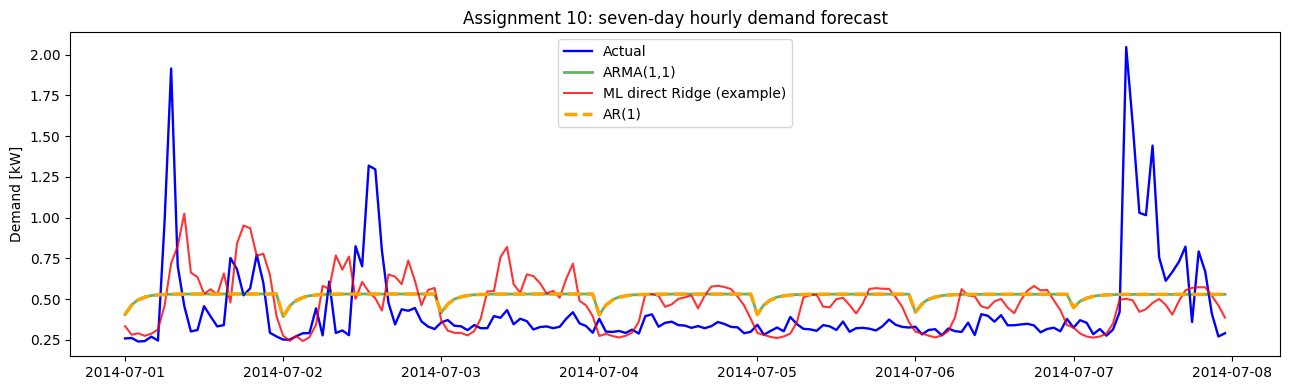

In [6]:
# Build 24 direct ML models from historical forecast origins.
# Each training example uses only the 24 hours BEFORE the forecast day.
# Target values are the following 24 hours, never used as input.
def build_direct_examples(history):
    arr = history.to_numpy()
    origins = np.arange(24, len(arr)-24+1, 24)
    X, Y = [], []
    for i in origins:
        # Last 24 observed demand values, newest first.
        lag24 = arr[i-24:i][::-1]
        X.append(lag24)
        Y.append(arr[i:i+24])
    return np.asarray(X), np.asarray(Y)

def fit_direct_ridge(history, alpha=10.0):
    X, Y = build_direct_examples(history)
    models = []
    for h in range(24):
        m = make_pipeline(StandardScaler(), Ridge(alpha=alpha))
        m.fit(X, Y[:, h])
        models.append(m)
    return models

def predict_direct(models, history):
    last24 = history.iloc[-24:].to_numpy()[::-1].reshape(1, -1)
    return np.maximum(0, np.array([m.predict(last24)[0] for m in models]))

# Daily walk-forward. The actual test demand becomes available AFTER each day.
# Models are refitted at the beginning of each new day (expanding window).
all_rows = []
interval_day = None
for day in range(7):
    day_start = test.index[day*24]
    history = pd.concat([train, test.iloc[:day*24]])
    actual = test.iloc[day*24:(day+1)*24]

    # Statistical models from Assignment 8.
    ar1 = SARIMAX(history, order=(1,0,0), trend="c",
                  enforce_stationarity=True).fit(disp=False)
    arma11 = SARIMAX(history, order=(1,0,1), trend="c",
                     enforce_stationarity=True).fit(disp=False)
    fc_ar1 = ar1.get_forecast(steps=24)
    p_ar1 = np.maximum(0, np.asarray(fc_ar1.predicted_mean))
    p_arma = np.maximum(0, np.asarray(arma11.forecast(steps=24)))

    # Direct ML example from Practical 12. NB! I NEED LATER to Replace with the Task 9 winner.
    ridge_models = fit_direct_ridge(history)
    p_ml = predict_direct(ridge_models, history)

    # Four fixed baselines from Assignment 7, with no within-day updates.
    last = history.iloc[-1]
    b_last = np.repeat(last, 24)
    b_24 = history.iloc[-24:].to_numpy()
    b_168 = history.iloc[-168:-144].to_numpy()
    b_ma = np.repeat(history.iloc[-24:].mean(), 24)

    for h, ts in enumerate(actual.index):
        all_rows.append({"timestamp": ts, "day": day+1, "h": h+1,
                         "Actual": actual.iloc[h], "AR(1)": p_ar1[h],
                         "ARMA(1,1)": p_arma[h], "ML direct Ridge (example)": p_ml[h],
                         "Naive last value": b_last[h],
                         "Seasonal lag 24": b_24[h],
                         "Seasonal lag 168": b_168[h],
                         "Moving average 24h": b_ma[h]})

    # Store a model-based 80% prediction interval for the first test day.
    if day == 0:
        ci = np.asarray(fc_ar1.conf_int(alpha=0.20))
        interval_day = pd.DataFrame({"timestamp": actual.index, "h": np.arange(1,25),
                                     "Actual": actual.to_numpy(), "AR(1)": p_ar1,
                                     "Lower 80%": np.maximum(0, ci[:,0]),
                                     "Upper 80%": np.maximum(0, ci[:,1])})

results = pd.DataFrame(all_rows).set_index("timestamp")
models = ["AR(1)", "ARMA(1,1)", "ML direct Ridge (example)"]
baselines = ["Naive last value", "Seasonal lag 24", "Seasonal lag 168", "Moving average 24h"]
summary = pd.DataFrame({m: score(results.Actual, results[m]) for m in models+baselines}).T
print("Seven-day forecast comparison:")
display(summary.round(3).sort_values("nRMSE [%]"))

# Plot actual demand and model forecasts
plt.figure(figsize=(13, 4))

# Actual demand
plt.plot(results.index, results["Actual"],
         label="Actual", color="blue", linewidth=1.7)

# ARMA(1,1) - green solid line
plt.plot(results.index, results["ARMA(1,1)"],
         label="ARMA(1,1)", color="green",
         linewidth=2, alpha=0.6, zorder=2)

# ML Ridge - red line
plt.plot(results.index, results["ML direct Ridge (example)"],
         label="ML direct Ridge (example)",
         color="red", linewidth=1.5, alpha=0.8)

# AR(1) - orange dashed line, drawn on top
plt.plot(results.index, results["AR(1)"],
         label="AR(1)", color="orange",
         linestyle="--", linewidth=2.5, zorder=5)

plt.title("Assignment 10: seven-day hourly demand forecast")
plt.ylabel("Demand [kW]")
plt.legend()
plt.tight_layout()
plt.show()


**Comment to 10.1:** I used AR(1) and ARMA(1,1) as statistical models and Direct Ridge as an example machine-learning model.

AR(1) and ARMA(1,1) use recursive forecasting, while Ridge uses 24 direct models.

Assignment 9 is scheduled after Assignment 10. Therefore, I used Ridge as a provisional ML model. Its final configuration can be reviewed after completing Assignment 9.


**TASK 10.2.** Compare the forecasts against the baselines fixed in Task 7. Report the error per horizon step h = 1, . . . , 24, and comment on the shape of the curve.

,AR(1),"ARMA(1,1)",ML direct Ridge (example),Naive last value,Seasonal lag 24,Seasonal lag 168,Moving average 24h
h,,,,,,,
1,19.06,19.27,10.35,8.89,8.25,10.34,31.17
2,31.70,32.20,7.67,5.87,12.12,13.21,31.31
3,36.98,37.45,8.62,4.78,6.64,10.63,32.08
4,40.37,40.72,8.35,8.22,5.86,8.26,31.36
5,42.71,42.96,5.25,6.11,4.35,33.31,30.70
6,38.14,38.29,11.77,16.29,18.00,29.19,27.64
7,49.73,49.78,43.45,48.48,67.45,39.53,34.25
8,103.04,103.03,90.38,117.97,146.18,136.22,95.70
9,112.60,112.59,117.82,122.68,124.36,116.85,123.55


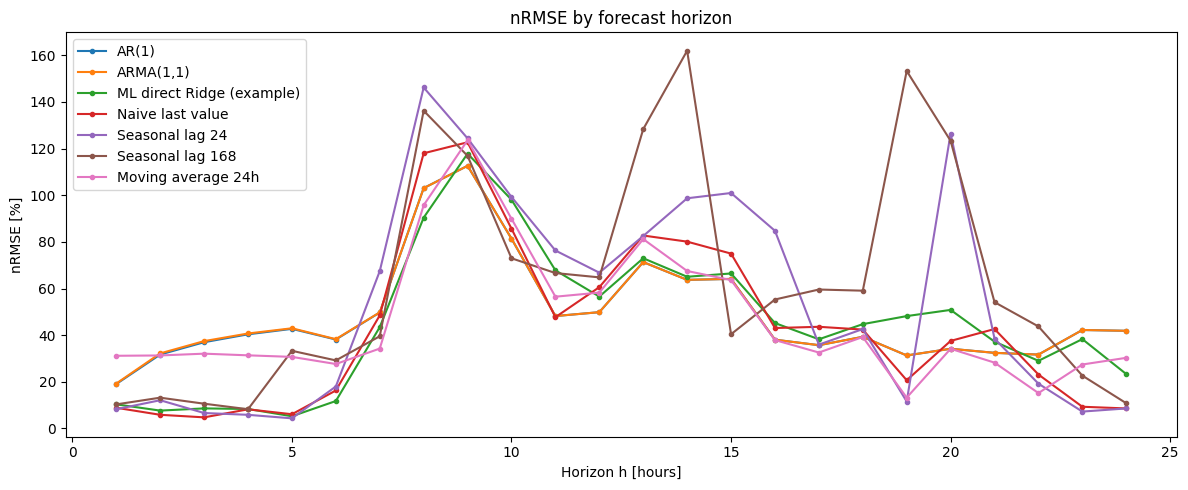

In [3]:
# Calculate nRMSE separately for each forecast hour using the seven test days.
# The same training mean is used as in Task 7.
by_h = []
for h, g in results.groupby("h"):
    row = {"h": h}
    for m in models+baselines:
        row[m] = score(g.Actual, g[m])["nRMSE [%]"]
    by_h.append(row)
horizon_scores = pd.DataFrame(by_h).set_index("h")
display(horizon_scores.round(2))

ax = horizon_scores.plot(figsize=(12,5), marker=".", title="nRMSE by forecast horizon")
ax.set(xlabel="Horizon h [hours]", ylabel="nRMSE [%]")
plt.tight_layout()
plt.show()


**Answer 10.2:** I compared three forecasting models with four baselines for all 24 forecast hours.

AR(1) and ARMA(1,1) produced almost identical results. Forecast errors were highest around hours 8–10, when electricity demand had large peaks.

Errors did not increase steadily with the horizon. They depended mainly on the hour of the day and unexpected consumption peaks.

**Task 10.3.** For each of the 7 days, mark whether your best model beat the seasonal naïve baseline. If it lost on any day, explain what happened on that day using the data.

Best of the evaluated models: AR(1)


,Day,Date,Model MAE [kW],Seasonal MAE [kW],Model nRMSE [%],Seasonal nRMSE [%],Beat seasonal naive?
0,1,2014-07-01,0.240,0.311,66.090,106.783,True
1,2,2014-07-02,0.230,0.312,54.706,87.075,True
2,3,2014-07-03,0.171,0.196,33.206,62.395,True
3,4,2014-07-04,0.187,0.034,36.219,7.712,False
4,5,2014-07-05,0.192,0.032,36.701,7.477,False
5,6,2014-07-06,0.188,0.034,36.102,7.310,False
6,7,2014-07-07,0.333,0.357,89.579,105.638,True


Day 4: actual peak 0.406 kW at 2014-07-04 08:00:00+00:00; model forecast 0.529 kW; seasonal forecast 0.395 kW


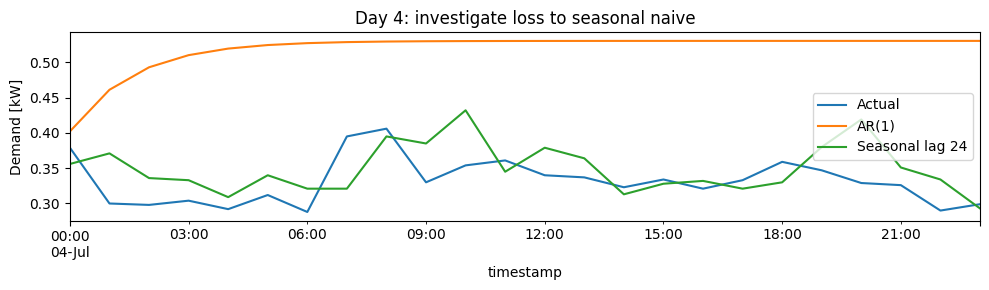

Day 5: actual peak 0.390 kW at 2014-07-05 05:00:00+00:00; model forecast 0.524 kW; seasonal forecast 0.312 kW


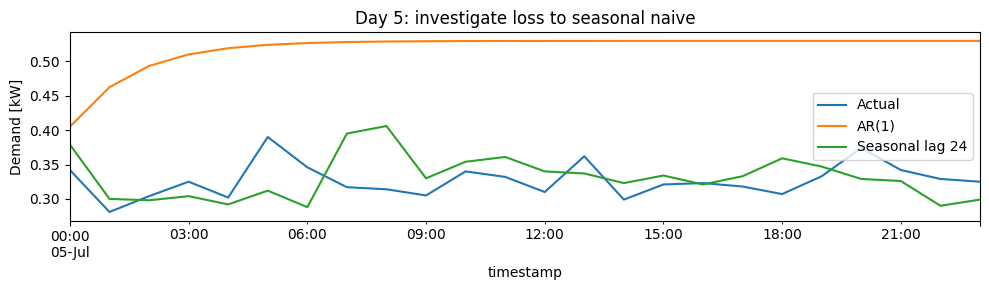

Day 6: actual peak 0.407 kW at 2014-07-06 10:00:00+00:00; model forecast 0.529 kW; seasonal forecast 0.340 kW


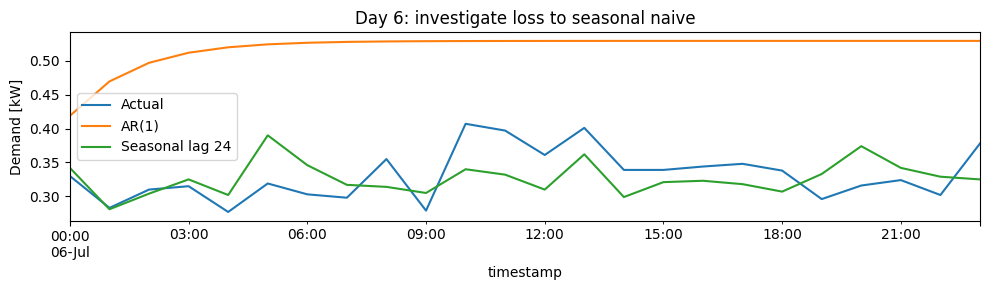

In [4]:
# Choose the best non-baseline model by the seven-day nRMSE.
# This selection is descriptive: for a fully unbiased final test, fix the winner on validation data.
best_model = summary.loc[models, "nRMSE [%]"].idxmin()
print("Best of the evaluated models:", best_model)
rows = []
for day, g in results.groupby("day"):
    best = score(g.Actual, g[best_model])
    seasonal = score(g.Actual, g["Seasonal lag 24"])
    rows.append({"Day": day, "Date": str(g.index[0].date()),
                 "Model MAE [kW]": best["MAE [kW]"],
                 "Seasonal MAE [kW]": seasonal["MAE [kW]"],
                 "Model nRMSE [%]": best["nRMSE [%]"],
                 "Seasonal nRMSE [%]": seasonal["nRMSE [%]"],
                 "Beat seasonal naive?": best["nRMSE [%]"] < seasonal["nRMSE [%]"]})
daily = pd.DataFrame(rows)
display(daily.round(3))

# Inspect days when the chosen model loses.
for day in daily.loc[~daily["Beat seasonal naive?"], "Day"]:
    g = results[results.day == day]
    peak = g.Actual.idxmax()
    print(f"Day {day}: actual peak {g.Actual.max():.3f} kW at {peak}; "
          f"model forecast {g.loc[peak,best_model]:.3f} kW; "
          f"seasonal forecast {g.loc[peak,'Seasonal lag 24']:.3f} kW")
    ax = g[["Actual", best_model, "Seasonal lag 24"]].plot(
        figsize=(10,3), title=f"Day {day}: investigate loss to seasonal naive")
    ax.set_ylabel("Demand [kW]")
    plt.tight_layout(); plt.show()


**Answer to 10.3**

I compared my best model, AR(1), with the seasonal naïve baseline (lag-24) for each of the seven days.

AR(1) performed better on days 1, 2, 3 and 7. It performed worse on days 4, 5 and 6.

On these three days, actual electricity demand was low and stable, mostly between 0.3 and 0.4 kW. AR(1) predicted about 0.53 kW, which was too high. The seasonal naïve model used the previous day's demand and followed the actual values more closely.

For example, on day 4, AR(1) had an MAE of 0.187 kW, compared with only 0.034 kW for the seasonal baseline.

This shows that AR(1) does not adapt quickly to periods of unusually low demand.


**Task 10.4.** Produce 80% prediction intervals for at least one model and one forecast day.

(a) Show how interval width changes with the horizon and explain why.

,timestamp,h,Actual,AR(1),Lower 80%,Upper 80%,Width [kW],Inside 80%
0,2014-07-01 00:00:00+00:00,1,0.258,0.404,0.000,0.810,0.810,True
1,2014-07-01 01:00:00+00:00,2,0.261,0.463,0.002,0.923,0.921,True
2,2014-07-01 02:00:00+00:00,3,0.239,0.494,0.018,0.970,0.951,True
3,2014-07-01 03:00:00+00:00,4,0.242,0.511,0.031,0.991,0.960,True
4,2014-07-01 04:00:00+00:00,5,0.269,0.520,0.039,1.001,0.962,True
5,2014-07-01 05:00:00+00:00,6,0.245,0.525,0.044,1.007,0.963,True
6,2014-07-01 06:00:00+00:00,7,0.972,0.528,0.046,1.009,0.963,True
7,2014-07-01 07:00:00+00:00,8,1.915,0.529,0.048,1.011,0.963,False
8,2014-07-01 08:00:00+00:00,9,0.703,0.530,0.048,1.012,0.963,True
9,2014-07-01 09:00:00+00:00,10,0.456,0.531,0.049,1.012,0.963,True


Observed coverage on this day: 95.8%


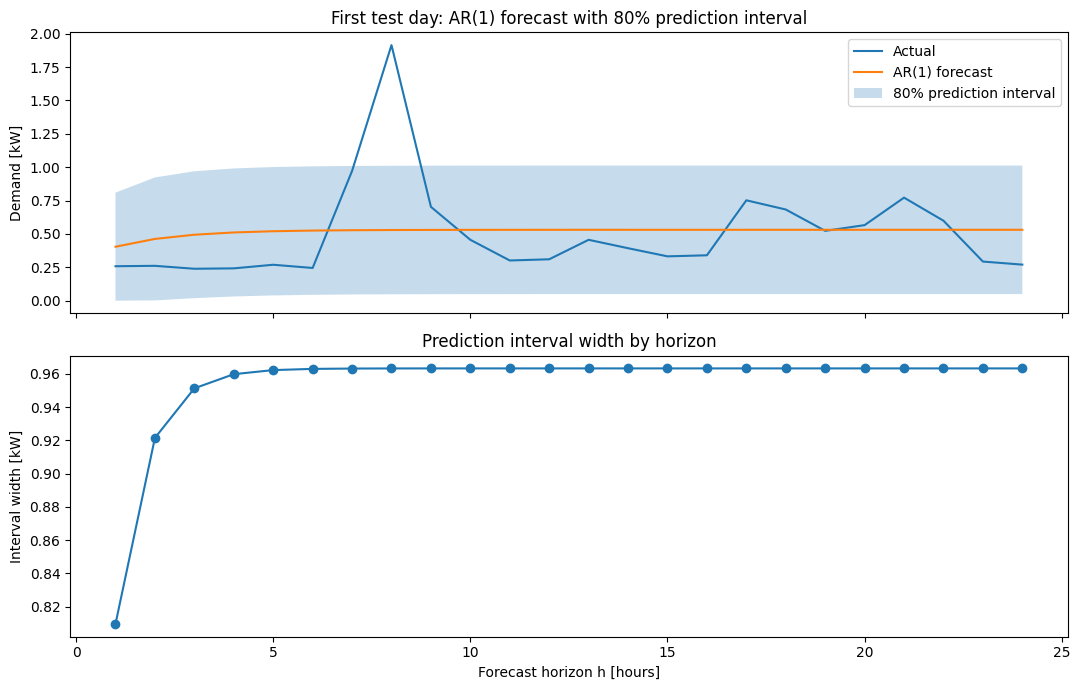

In [5]:
# Use the AR(1) forecast distribution for the first test day.
# An 80% prediction interval is for an individual future demand value.
# Non-negative lower bounds are clipped to respect the physical demand constraint.
interval_day["Width [kW]"] = interval_day["Upper 80%"] - interval_day["Lower 80%"]
interval_day["Inside 80%"] = (interval_day.Actual >= interval_day["Lower 80%"]) & (
    interval_day.Actual <= interval_day["Upper 80%"])
display(interval_day.round(3))
print("Observed coverage on this day:", f"{100*interval_day['Inside 80%'].mean():.1f}%")

fig, axs = plt.subplots(2,1,figsize=(11,7),sharex=True)
axs[0].plot(interval_day.h, interval_day.Actual, label="Actual")
axs[0].plot(interval_day.h, interval_day["AR(1)"], label="AR(1) forecast")
axs[0].fill_between(interval_day.h.to_numpy(), interval_day["Lower 80%"].to_numpy(),
                    interval_day["Upper 80%"].to_numpy(), alpha=0.25, label="80% prediction interval")
axs[0].set(ylabel="Demand [kW]", title="First test day: AR(1) forecast with 80% prediction interval")
axs[0].legend()
axs[1].plot(interval_day.h, interval_day["Width [kW]"], marker="o")
axs[1].set(xlabel="Forecast horizon h [hours]", ylabel="Interval width [kW]",
           title="Prediction interval width by horizon")
plt.tight_layout();plt.show()


**Answer 10.4(a):**

I calculated an 80% prediction interval for the AR(1) model on the first test day.

The interval width increases from 0.81 kW at hour 1 to approximately 0.96 kW after six hours. It then remains almost constant.

This happens because forecast uncertainty increases with the horizon but approaches a stable level in the AR(1) model.

One large morning consumption peak falls outside the interval.